### Import Libraries

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.figsize"] = (10, 6)
plt.rcParams["axes.titlesize"] = 14
plt.rcParams["axes.labelsize"] = 11

### Load Dataset

In [9]:
df = pd.read_csv("../data/raw/customer_shopping_behavior.csv")

print(f"Dataset loaded successfully: {df.shape[0]:,} rows × {df.shape[1]} columns")

Dataset loaded successfully: 3,900 rows × 18 columns


### Initial Data Inspection

In [3]:
df.head()

,Customer ID,Age,Gender,Item Purchased,Category,Purchase Amount (USD),Location,Size,Color,Season,Review Rating,Subscription Status,Shipping Type,Discount Applied,Promo Code Used,Previous Purchases,Payment Method,Frequency of Purchases
0,1,55,Male,Blouse,Clothing,53,Kentucky,L,Gray,Winter,3.10,Yes,Express,Yes,Yes,14,Venmo,Fortnightly
1,2,19,Male,Sweater,Clothing,64,Maine,L,Maroon,Winter,3.10,Yes,Express,Yes,Yes,2,Cash,Fortnightly
2,3,50,Male,Jeans,Clothing,73,Massachusetts,S,Maroon,Spring,3.10,Yes,Free Shipping,Yes,Yes,23,Credit Card,Weekly
3,4,21,Male,Sandals,Footwear,90,Rhode Island,M,Maroon,Spring,3.50,Yes,Next Day Air,Yes,Yes,49,PayPal,Weekly
4,5,45,Male,Blouse,Clothing,49,Oregon,M,Turquoise,Spring,2.70,Yes,Free Shipping,Yes,Yes,31,PayPal,Annually


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3900 entries, 0 to 3899
Data columns (total 18 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Customer ID             3900 non-null   int64  
 1   Age                     3900 non-null   int64  
 2   Gender                  3900 non-null   object 
 3   Item Purchased          3900 non-null   object 
 4   Category                3900 non-null   object 
 5   Purchase Amount (USD)   3900 non-null   int64  
 6   Location                3900 non-null   object 
 7   Size                    3900 non-null   object 
 8   Color                   3900 non-null   object 
 9   Season                  3900 non-null   object 
 10  Review Rating           3863 non-null   float64
 11  Subscription Status     3900 non-null   object 
 12  Shipping Type           3900 non-null   object 
 13  Discount Applied        3900 non-null   object 
 14  Promo Code Used         3900 non-null   

In [5]:
# Descriptive statistics for numerical variables
display(df.describe().T)

,count,mean,std,min,25%,50%,75%,max
Customer ID,"3,900.00","1,950.50","1,125.98",1.00,975.75,"1,950.50","2,925.25","3,900.00"
Age,"3,900.00",44.07,15.21,18.00,31.00,44.00,57.00,70.00
Purchase Amount (USD),"3,900.00",59.76,23.69,20.00,39.00,60.00,81.00,100.00
Review Rating,"3,863.00",3.75,0.72,2.50,3.10,3.80,4.40,5.00
Previous Purchases,"3,900.00",25.35,14.45,1.00,13.00,25.00,38.00,50.00


In [6]:
# Cardinality and data types
profile = pd.DataFrame({
    "column": df.columns,
    "dtype": df.dtypes.astype(str).values,
    "unique_values": [df[col].nunique(dropna=True) for col in df.columns],
    "missing_values": df.isna().sum().values,
    "missing_%": (df.isna().mean().values * 100).round(2)
})

display(profile.sort_values(["missing_values", "unique_values"], ascending=[False, True]))

,column,dtype,unique_values,missing_values,missing_%
10,Review Rating,float64,26,37,0.95
2,Gender,object,2,0,0.00
11,Subscription Status,object,2,0,0.00
13,Discount Applied,object,2,0,0.00
14,Promo Code Used,object,2,0,0.00
4,Category,object,4,0,0.00
7,Size,object,4,0,0.00
9,Season,object,4,0,0.00
12,Shipping Type,object,6,0,0.00
16,Payment Method,object,6,0,0.00


### Data Quality Assessment

The goal is to identify issues before performing analysis.

### Checks
1. Missing values
2. Duplicate rows
3. Duplicate customer IDs
4. Invalid numeric ranges
5. Unexpected categorical values

In [7]:
# Missing values
missing = (
    df.isna()
      .sum()
      .to_frame("missing_values")
      .assign(missing_pct=lambda x: (x["missing_values"] / len(df) * 100).round(2))
      .query("missing_values > 0")
      .sort_values("missing_values", ascending=False)
)

display(missing if not missing.empty else pd.DataFrame({"status": ["No missing values"]}))

,missing_values,missing_pct
Review Rating,37,0.95


In [8]:
# Duplicate checks
print(f"Duplicate rows: {df.duplicated().sum():,}")
print(f"Duplicate Customer IDs: {df['Customer ID'].duplicated().sum():,}")
print(f"Unique Customer IDs: {df['Customer ID'].nunique():,}")

Duplicate rows: 0
Duplicate Customer IDs: 0
Unique Customer IDs: 3,900


In [9]:
# Range checks for important numerical fields
range_checks = pd.DataFrame({
    "metric": [
        "Age",
        "Purchase Amount (USD)",
        "Review Rating",
        "Previous Purchases"
    ],
    "min": [
        df["Age"].min(),
        df["Purchase Amount (USD)"].min(),
        df["Review Rating"].min(),
        df["Previous Purchases"].min()
    ],
    "max": [
        df["Age"].max(),
        df["Purchase Amount (USD)"].max(),
        df["Review Rating"].max(),
        df["Previous Purchases"].max()
    ]
})

display(range_checks)

,metric,min,max
0,Age,18.00,70.00
1,Purchase Amount (USD),20.00,100.00
2,Review Rating,2.50,5.00
3,Previous Purchases,1.00,50.00


### Data Cleaning

#### Cleaning decisions

- Standardize column names to `snake_case`.
- Impute missing `review_rating` values using the **median rating within the corresponding product category**.
- Keep the original `promo_code_used` column during validation. It will only be removed if it contains the same information as `discount_applied`.
- Create analytical features without modifying the raw source file.

In [11]:
# Work on a copy so the raw DataFrame remains available for comparison.
df_clean = df.copy()

# Standardize column names
df_clean.columns = (
    df_clean.columns
    .str.strip()
    .str.lower()
    .str.replace(r"[^a-z0-9]+", "_", regex=True)
    .str.strip("_")
)

# Make the main metric easier to reference
df_clean = df_clean.rename(
    columns={"purchase_amount_usd": "purchase_amount"}
)

df_clean.columns.tolist()

['customer_id',
 'age',
 'gender',
 'item_purchased',
 'category',
 'purchase_amount',
 'location',
 'size',
 'color',
 'season',
 'review_rating',
 'subscription_status',
 'shipping_type',
 'discount_applied',
 'promo_code_used',
 'previous_purchases',
 'payment_method',
 'frequency_of_purchases']

In [12]:
# Missing review ratings before imputation
missing_reviews_before = df_clean["review_rating"].isna().sum()

# Category-level median imputation
df_clean["review_rating"] = (
    df_clean.groupby("category")["review_rating"]
    .transform(lambda s: s.fillna(s.median()))
)

missing_reviews_after = df_clean["review_rating"].isna().sum()

print(f"Missing review ratings before: {missing_reviews_before}")
print(f"Missing review ratings after : {missing_reviews_after}")

Missing review ratings before: 37
Missing review ratings after : 0


In [13]:
# Validate whether promo_code_used duplicates discount_applied.
promo_matches_discount = (
    df_clean["discount_applied"].astype(str).str.strip().str.lower()
    ==
    df_clean["promo_code_used"].astype(str).str.strip().str.lower()
).all()

print(f"Promo-code and discount indicators identical: {promo_matches_discount}")

if promo_matches_discount:
    df_clean = df_clean.drop(columns="promo_code_used")
    print("Dropped 'promo_code_used' because it contains no additional information.")
else:
    print("Retained 'promo_code_used' because it contains information different from 'discount_applied'.")

Promo-code and discount indicators identical: True
Dropped 'promo_code_used' because it contains no additional information.


### Feature Engineering

A few derived fields make the analysis easier to interpret.

#### New features

- **age_group:** business-friendly age bands
- **purchase_frequency_days:** approximate interval represented by the categorical frequency
- **is_subscriber:** binary representation of subscription status
- **has_discount:** binary representation of discount usage

In [14]:
# Business-friendly age bands
age_bins = [0, 25, 35, 45, 55, 65, np.inf]
age_labels = ["18–25", "26–35", "36–45", "46–55", "56–65", "66+"]

df_clean["age_group"] = pd.cut(
    df_clean["age"],
    bins=age_bins,
    labels=age_labels,
    include_lowest=True
)

# Approximate purchase intervals
frequency_mapping = {
    "Weekly": 7,
    "Fortnightly": 14,
    "Bi-Weekly": 14,
    "Monthly": 30,
    "Quarterly": 90,
    "Every 3 Months": 90,
    "Annually": 365
}

df_clean["purchase_frequency_days"] = (
    df_clean["frequency_of_purchases"].map(frequency_mapping)
)

# Binary analytical flags
df_clean["is_subscriber"] = df_clean["subscription_status"].map({"Yes": 1, "No": 0})
df_clean["has_discount"] = df_clean["discount_applied"].map({"Yes": 1, "No": 0})

display(
    df_clean[
        [
            "age", "age_group",
            "frequency_of_purchases", "purchase_frequency_days",
            "subscription_status", "is_subscriber",
            "discount_applied", "has_discount"
        ]
    ].head(10)
)

,age,age_group,frequency_of_purchases,purchase_frequency_days,subscription_status,is_subscriber,discount_applied,has_discount
0,55,46–55,Fortnightly,14,Yes,1,Yes,1
1,19,18–25,Fortnightly,14,Yes,1,Yes,1
2,50,46–55,Weekly,7,Yes,1,Yes,1
3,21,18–25,Weekly,7,Yes,1,Yes,1
4,45,36–45,Annually,365,Yes,1,Yes,1
5,46,46–55,Weekly,7,Yes,1,Yes,1
6,63,56–65,Quarterly,90,Yes,1,Yes,1
7,27,26–35,Weekly,7,Yes,1,Yes,1
8,26,26–35,Annually,365,Yes,1,Yes,1
9,57,56–65,Quarterly,90,Yes,1,Yes,1


In [15]:
# Validate engineered features
print("Rows with unmapped purchase frequency:",
      df_clean["purchase_frequency_days"].isna().sum())

print("Rows with unmapped subscription status:",
      df_clean["is_subscriber"].isna().sum())

print("Rows with unmapped discount status:",
      df_clean["has_discount"].isna().sum())

Rows with unmapped purchase frequency: 0
Rows with unmapped subscription status: 0
Rows with unmapped discount status: 0


### Final Data Quality Validation

In [16]:
validation = {
    "rows": len(df_clean),
    "columns": len(df_clean.columns),
    "duplicate_rows": df_clean.duplicated().sum(),
    "duplicate_customer_ids": df_clean["customer_id"].duplicated().sum(),
    "missing_values": int(df_clean.isna().sum().sum()),
    "negative_purchase_amounts": int((df_clean["purchase_amount"] < 0).sum()),
    "invalid_ratings": int((~df_clean["review_rating"].between(1, 5)).sum()),
}

display(pd.Series(validation, name="value").to_frame())

,value
rows,3900
columns,21
duplicate_rows,0
duplicate_customer_ids,0
missing_values,0
negative_purchase_amounts,0
invalid_ratings,0


In [17]:
df_clean.head()

,customer_id,age,gender,item_purchased,category,purchase_amount,location,size,color,season,review_rating,subscription_status,shipping_type,discount_applied,previous_purchases,payment_method,frequency_of_purchases,age_group,purchase_frequency_days,is_subscriber,has_discount
0,1,55,Male,Blouse,Clothing,53,Kentucky,L,Gray,Winter,3.10,Yes,Express,Yes,14,Venmo,Fortnightly,46–55,14,1,1
1,2,19,Male,Sweater,Clothing,64,Maine,L,Maroon,Winter,3.10,Yes,Express,Yes,2,Cash,Fortnightly,18–25,14,1,1
2,3,50,Male,Jeans,Clothing,73,Massachusetts,S,Maroon,Spring,3.10,Yes,Free Shipping,Yes,23,Credit Card,Weekly,46–55,7,1,1
3,4,21,Male,Sandals,Footwear,90,Rhode Island,M,Maroon,Spring,3.50,Yes,Next Day Air,Yes,49,PayPal,Weekly,18–25,7,1,1
4,5,45,Male,Blouse,Clothing,49,Oregon,M,Turquoise,Spring,2.70,Yes,Free Shipping,Yes,31,PayPal,Annually,36–45,365,1,1


## Exploratory Data Analysis

### Questions

1. Who are the customers?
2. What products and categories drive purchasing activity?
3. How does purchasing behavior vary across customer segments?
4. What is the relationship between discounts, subscriptions, and purchasing?
5. What can customer ratings tell us about product performance?
6. Which patterns should be investigated further in SQL and Power BI?

### Customer Demographics

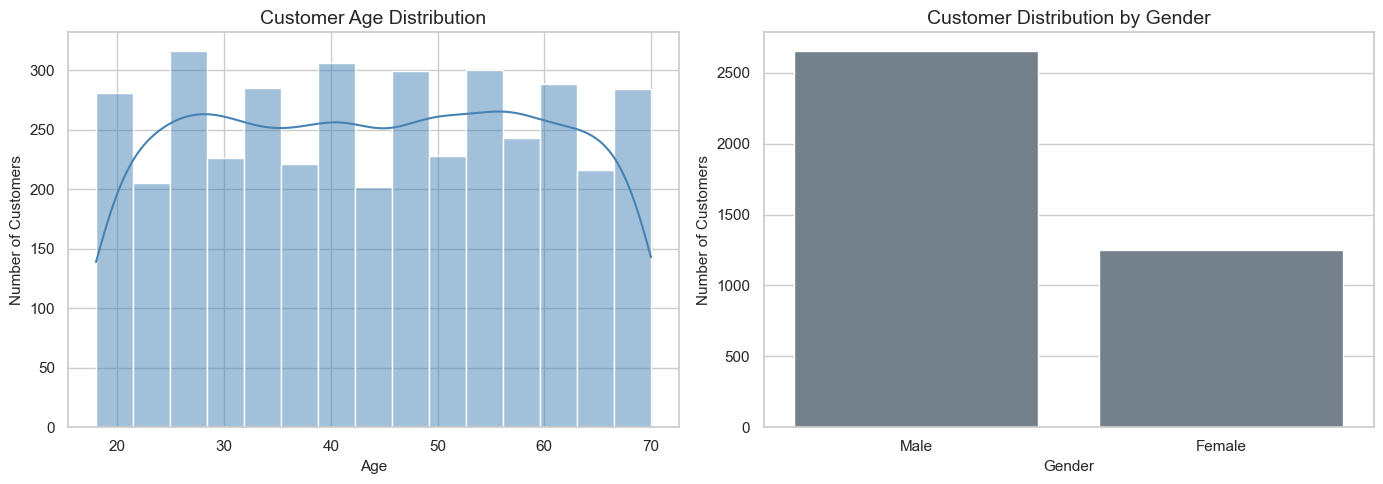

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(
    data=df_clean,
    x="age",
    bins=15,
    kde=True,
    color="steelblue",
    ax=axes[0]
)
axes[0].set_title("Customer Age Distribution")
axes[0].set_xlabel("Age")
axes[0].set_ylabel("Number of Customers")

gender_order = df_clean["gender"].value_counts().index
sns.countplot(
    data=df_clean,
    color="slategray",
    x="gender",
    order=gender_order,
    ax=axes[1]
)
axes[1].set_title("Customer Distribution by Gender")
axes[1].set_xlabel("Gender")
axes[1].set_ylabel("Number of Customers")

plt.tight_layout()
plt.show()

In [19]:
age_summary = (
    df_clean.groupby("age_group", observed=False)
    .agg(
        customers=("customer_id", "nunique"),
        avg_purchase=("purchase_amount", "mean"),
        total_revenue=("purchase_amount", "sum")
    )
    .reset_index()
)

display(age_summary)

,age_group,customers,avg_purchase,total_revenue
0,18–25,571,60.65,34630
1,26–35,742,59.76,44342
2,36–45,729,59.31,43234
3,46–55,753,60.58,45619
4,56–65,750,59.14,44352
5,66+,355,58.88,20904


### Product and Category Performance

**Which categories and products account for the most purchasing activity and revenue?**

In [20]:
category_summary = (
    df_clean.groupby("category")
    .agg(
        purchases=("customer_id", "count"),
        revenue=("purchase_amount", "sum"),
        avg_purchase=("purchase_amount", "mean"),
        avg_rating=("review_rating", "mean")
    )
    .sort_values("revenue", ascending=False)
)

display(category_summary.round(2))

,purchases,revenue,avg_purchase,avg_rating
category,,,,
Clothing,1737,104264,60.03,3.72
Accessories,1240,74200,59.84,3.77
Footwear,599,36093,60.26,3.79
Outerwear,324,18524,57.17,3.75


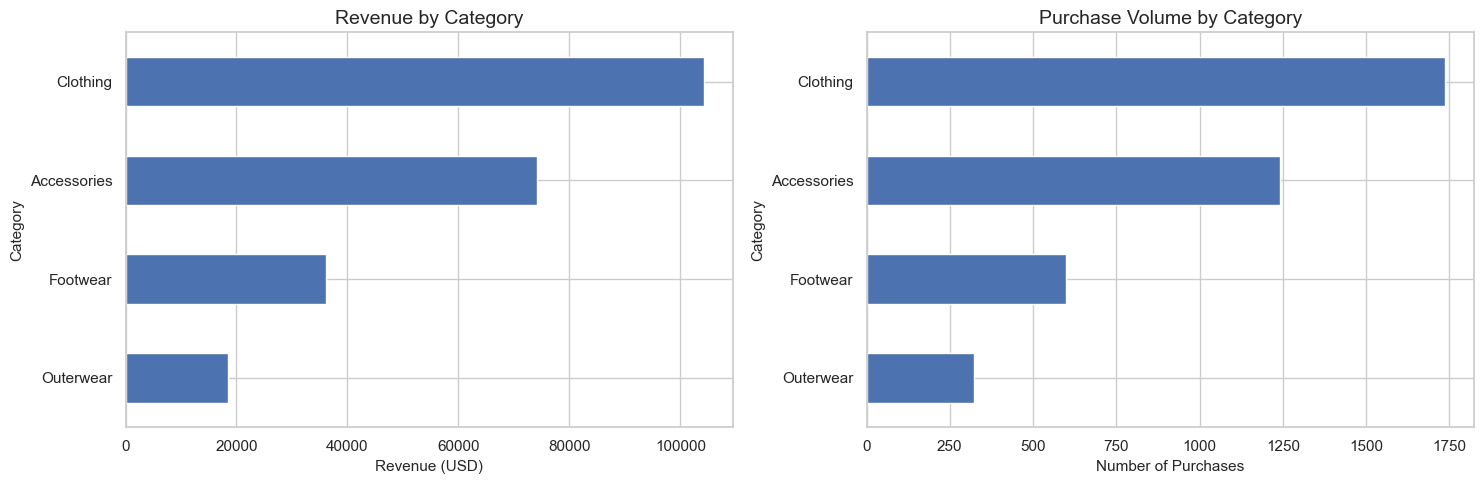

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

category_revenue = category_summary.sort_values("revenue", ascending=True)
category_revenue["revenue"].plot(
    kind="barh",
    ax=axes[0]
)
axes[0].set_title("Revenue by Category")
axes[0].set_xlabel("Revenue (USD)")
axes[0].set_ylabel("Category")

category_purchase = category_summary.sort_values("purchases", ascending=True)
category_purchase["purchases"].plot(
    kind="barh",
    ax=axes[1]
)
axes[1].set_title("Purchase Volume by Category")
axes[1].set_xlabel("Number of Purchases")
axes[1].set_ylabel("Category")

plt.tight_layout()
plt.show()

In [22]:
# Top products by revenue
product_summary = (
    df_clean.groupby("item_purchased")
    .agg(
        purchases=("customer_id", "count"),
        revenue=("purchase_amount", "sum"),
        avg_purchase=("purchase_amount", "mean"),
        avg_rating=("review_rating", "mean")
    )
    .sort_values("revenue", ascending=False)
)

display(product_summary.head(10).round(2))

,purchases,revenue,avg_purchase,avg_rating
item_purchased,,,,
Blouse,171,10410,60.88,3.68
Shirt,169,10332,61.14,3.62
Dress,166,10320,62.17,3.75
Pants,171,10090,59.01,3.72
Jewelry,171,10010,58.54,3.76
Sunglasses,161,9649,59.93,3.75
Belt,161,9635,59.84,3.76
Scarf,157,9561,60.90,3.71
Sweater,164,9462,57.70,3.76


### Purchasing Behavouir

**How frequently do customers purchase, and how does this relate to previous purchases?**

In [23]:
frequency_summary = (
    df_clean.groupby("frequency_of_purchases")
    .agg(
        customers=("customer_id", "nunique"),
        avg_purchase=("purchase_amount", "mean"),
        avg_previous_purchases=("previous_purchases", "mean")
    )
    .sort_values("avg_previous_purchases", ascending=False)
)

display(frequency_summary.round(2))

,customers,avg_purchase,avg_previous_purchases
frequency_of_purchases,,,
Quarterly,563,59.98,26.85
Weekly,539,58.97,25.77
Monthly,553,59.33,25.28
Fortnightly,542,59.05,25.27
Every 3 Months,584,60.08,24.96
Bi-Weekly,547,60.69,24.79
Annually,572,60.17,24.56


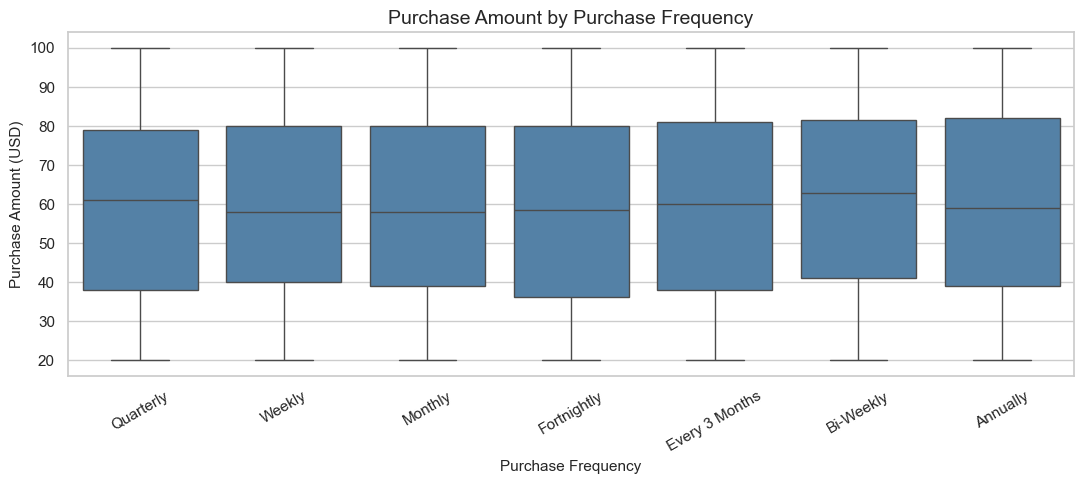

In [24]:
plt.figure(figsize=(11, 5))

sns.boxplot(
    data=df_clean,
    color="steelblue",
    x="frequency_of_purchases",
    y="purchase_amount",
    order=frequency_summary.index
)

plt.title("Purchase Amount by Purchase Frequency")
plt.xlabel("Purchase Frequency")
plt.ylabel("Purchase Amount (USD)")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

### Subscription Analysis

**Do subscribers exhibit different purchasing behavior from non-subscribers?**

In [25]:
subscription_summary = (
    df_clean.groupby("subscription_status")
    .agg(
        customers=("customer_id", "nunique"),
        avg_purchase=("purchase_amount", "mean"),
        total_revenue=("purchase_amount", "sum"),
        avg_previous_purchases=("previous_purchases", "mean"),
        avg_rating=("review_rating", "mean"),
        discount_usage_pct=("has_discount", "mean")
    )
)

subscription_summary["discount_usage_pct"] *= 100

display(subscription_summary.round(2))

,customers,avg_purchase,total_revenue,avg_previous_purchases,avg_rating,discount_usage_pct
subscription_status,,,,,,
No,2847,59.87,170436,25.08,3.75,21.92
Yes,1053,59.49,62645,26.08,3.75,100.00


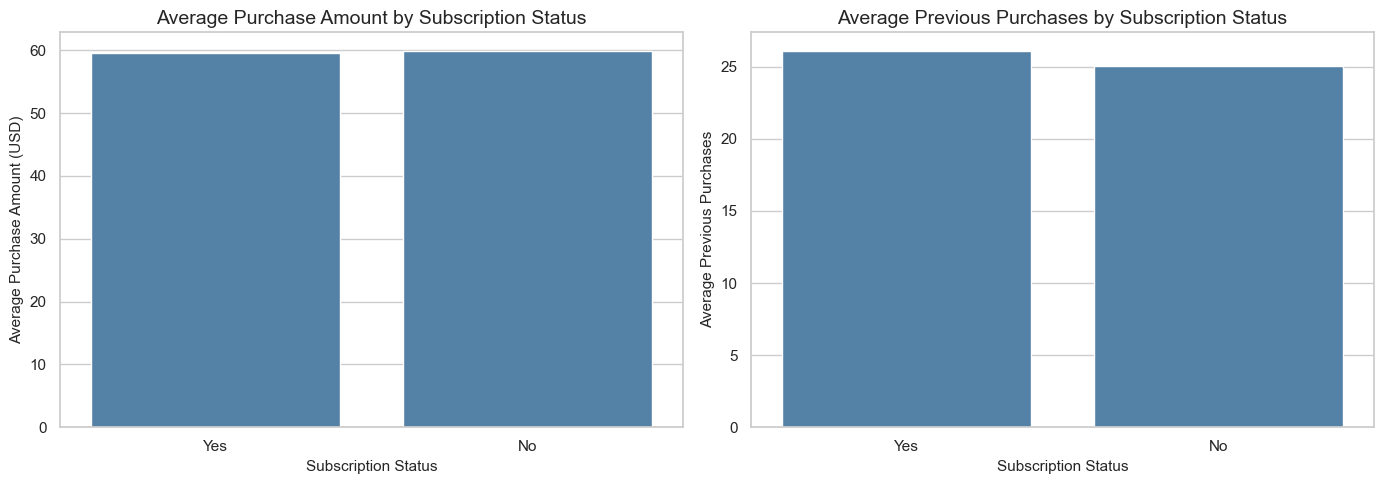

In [26]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.barplot(
    data=df_clean,
    color="steelblue",
    x="subscription_status",
    y="purchase_amount",
    estimator="mean",
    errorbar=None,
    ax=axes[0]
)
axes[0].set_title("Average Purchase Amount by Subscription Status")
axes[0].set_xlabel("Subscription Status")
axes[0].set_ylabel("Average Purchase Amount (USD)")

sns.barplot(
    data=df_clean,
    color="steelblue",
    x="subscription_status",
    y="previous_purchases",
    estimator="mean",
    errorbar=None,
    ax=axes[1]
)
axes[1].set_title("Average Previous Purchases by Subscription Status")
axes[1].set_xlabel("Subscription Status")
axes[1].set_ylabel("Average Previous Purchases")

plt.tight_layout()
plt.show()

### Discount & Promotional Behavior

**How is discount usage distributed, and how does it differ across customer groups?**

In [27]:
discount_summary = (
    df_clean.groupby("discount_applied")
    .agg(
        purchases=("customer_id", "count"),
        avg_purchase=("purchase_amount", "mean"),
        total_revenue=("purchase_amount", "sum"),
        avg_previous_purchases=("previous_purchases", "mean")
    )
)

display(discount_summary.round(2))

,purchases,avg_purchase,total_revenue,avg_previous_purchases
discount_applied,,,,
No,2223,60.13,133670,25.06
Yes,1677,59.28,99411,25.74


In [28]:
discount_by_category = (
    pd.pivot_table(
        df_clean,
        index="category",
        columns="discount_applied",
        values="purchase_amount",
        aggfunc="mean"
    )
    .round(2)
)

display(discount_by_category)

discount_applied,No,Yes
category,,
Accessories,60.89,58.49
Clothing,60.22,59.75
Footwear,59.08,61.80
Outerwear,58.66,55.32


### Customer Reviews

**Which categories combine purchasing activity with strong or weak customer ratings?**

In [29]:
rating_summary = (
    df_clean.groupby("category")
    .agg(
        avg_rating=("review_rating", "mean"),
        purchases=("customer_id", "count"),
        revenue=("purchase_amount", "sum")
    )
    .sort_values("avg_rating", ascending=False)
)

display(rating_summary.round(2))

,avg_rating,purchases,revenue
category,,,
Footwear,3.79,599,36093
Accessories,3.77,1240,74200
Outerwear,3.75,324,18524
Clothing,3.72,1737,104264


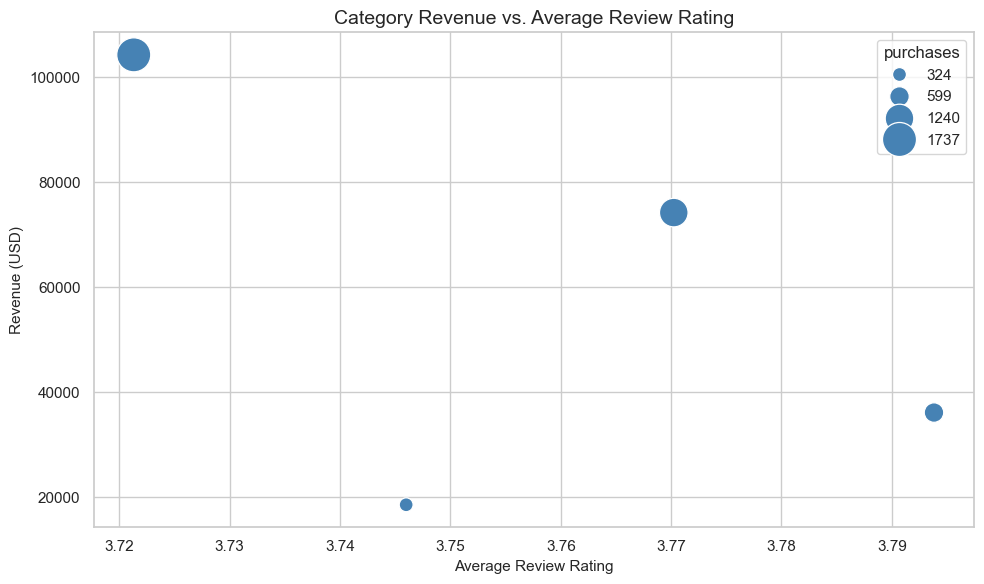

In [30]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=rating_summary,
    x="avg_rating",
    y="revenue",
    size="purchases",
    sizes=(100, 600),
    color="steelblue"
)

plt.title("Category Revenue vs. Average Review Rating")
plt.xlabel("Average Review Rating")
plt.ylabel("Revenue (USD)")
plt.tight_layout()
plt.show()

### Payment & Shipping Preferences

**Which payment and shipping methods are most commonly used?**

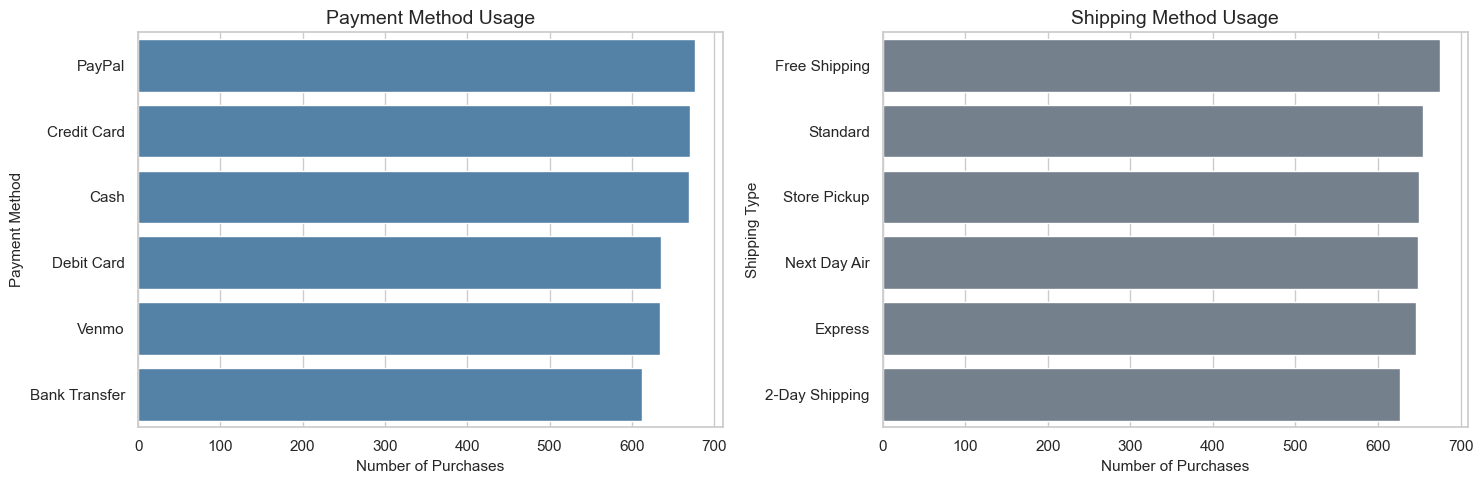

In [31]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

payment_counts = df_clean["payment_method"].value_counts()
sns.barplot(
    color="steelblue",
    x=payment_counts.values,
    y=payment_counts.index,
    ax=axes[0]
)
axes[0].set_title("Payment Method Usage")
axes[0].set_xlabel("Number of Purchases")
axes[0].set_ylabel("Payment Method")

shipping_counts = df_clean["shipping_type"].value_counts()
sns.barplot(
    color="slategray",
    x=shipping_counts.values,
    y=shipping_counts.index,
    ax=axes[1]
)
axes[1].set_title("Shipping Method Usage")
axes[1].set_xlabel("Number of Purchases")
axes[1].set_ylabel("Shipping Type")

plt.tight_layout()
plt.show()

### Correlation Analyis

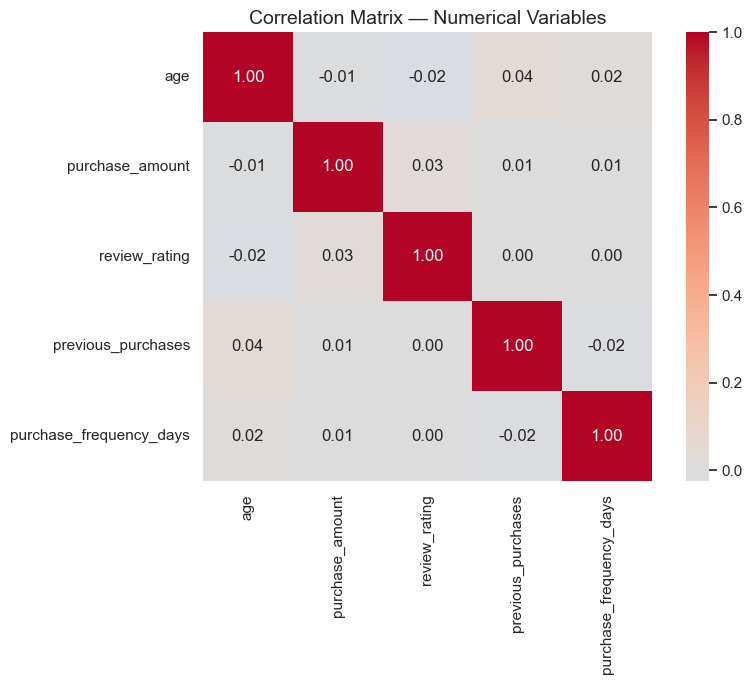

In [32]:
numeric_cols = [
    "age",
    "purchase_amount",
    "review_rating",
    "previous_purchases",
    "purchase_frequency_days"
]

corr = df_clean[numeric_cols].corr()

plt.figure(figsize=(9, 7))
sns.heatmap(
    corr,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    square=True
)
plt.title("Correlation Matrix — Numerical Variables")
plt.tight_layout()
plt.show()

### Bussiness Insight

In [33]:
kpis = {
    "Total Revenue": df_clean["purchase_amount"].sum(),
    "Total Purchases": len(df_clean),
    "Unique Customers": df_clean["customer_id"].nunique(),
    "Average Purchase": df_clean["purchase_amount"].mean(),
    "Average Rating": df_clean["review_rating"].mean(),
    "Subscriber Share (%)": df_clean["is_subscriber"].mean() * 100,
    "Discount Usage (%)": df_clean["has_discount"].mean() * 100,
}

kpi_table = pd.Series(kpis, name="Value").to_frame()
display(kpi_table.round(2))

,Value
Total Revenue,"233,081.00"
Total Purchases,"3,900.00"
Unique Customers,"3,900.00"
Average Purchase,59.76
Average Rating,3.75
Subscriber Share (%),27.00
Discount Usage (%),43.00


In [34]:
df_clean.to_csv("customer_shopping_behavior_clean.csv")

print(f"Shape: {df_clean.shape[0]:,} rows × {df_clean.shape[1]} columns")

Shape: 3,900 rows × 21 columns
